1. Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    hamming_loss
)

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    GlobalMaxPooling1D,
    SpatialDropout1D
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

2. Mount Google Drive and Load the Preprocessed Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train = pd.read_csv("/content/drive/MyDrive/Data_Science/models/train_cleaned.csv")

print(train.shape)

train.head()

(159547, 10)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,clean_text,word_count
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,explanation why the edits made under my userna...,47
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,d aww ! he match this background colour i am s...,17
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,hey man i am really not trying to edit war it ...,44
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,more i can not make any real suggestion on imp...,116
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,you sir are my hero any chance you remember wh...,15


3. Prepare Features, Labels, and Split the Dataset

In [ ]:
target_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

X = train["clean_text"]

y = train[target_columns]

In [ ]:
stratify_labels = (y.sum(axis=1) > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_labels
)

print(X_train.shape)
print(X_test.shape)

(127637,)
(31910,)


4. Tokenize the Text Data4. Tokenize the Text Data

In [ ]:
VOCAB_SIZE = 50000

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

In [ ]:
X_train_seq = tokenizer.texts_to_sequences(X_train)

X_test_seq = tokenizer.texts_to_sequences(X_test)

5. Pad Token Sequences

In [ ]:
MAX_LEN = 150

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

6. Build and Compile the BiLSTM Model

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    GlobalMaxPooling1D,
    Dense,
    Dropout
)

model = Sequential([
    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128
    ),

    SpatialDropout1D(0.2),

    Bidirectional(
        LSTM(
            128,
            return_sequences=True
        )
    ),

    GlobalMaxPooling1D(),

    Dense(128, activation="relu"),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dropout(0.2),

    Dense(6, activation="sigmoid")
])

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 128)       │     6,400,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 150, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 150, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 256)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,704,710 (25.58 MB)

 Trainable params: 6,704,710 (25.58 MB)

 Non-trainable params: 0 (0.00 B)

7. Configure Model Training Callbacks

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_bilstm.keras",
    save_best_only=True
)

8. Train the Improved BiLSTM Model

In [ ]:
history = model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=128,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/20
798/798 ━━━━━━━━━━━━━━━━━━━━ 41s 39ms/step - accuracy: 0.9715 - auc: 0.9267 - loss: 0.0906 - precision: 0.6779 - recall: 0.4148 - val_accuracy: 0.9799 - val_auc: 0.9758 - val_loss: 0.0549 - val_precision: 0.8542 - val_recall: 0.5749 - learning_rate: 0.0010
Epoch 2/20
798/798 ━━━━━━━━━━━━━━━━━━━━ 30s 38ms/step - accuracy: 0.9824 - auc: 0.9820 - loss: 0.0476 - precision: 0.8135 - recall: 0.6693 - val_accuracy: 0.9813 - val_auc: 0.9801 - val_loss: 0.0494 - val_precision: 0.8158 - val_recall: 0.6624 - learning_rate: 0.0010
Epoch 3/20
798/798 ━━━━━━━━━━━━━━━━━━━━ 30s 37ms/step - accuracy: 0.9841 - auc: 0.9875 - loss: 0.0416 - precision: 0.8271 - recall: 0.7109 - val_accuracy: 0.9803 - val_auc: 0.9775 - val_loss: 0.0518 - val_precision: 0.7614 - val_recall: 0.7088 - learning_rate: 0.0010
Epoch 4/20
798/798 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9856 - auc: 0.9906 - loss: 0.0367 - precision: 0.8368 - recall: 0.7437
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.000

9. Visualize Training and Validation Loss

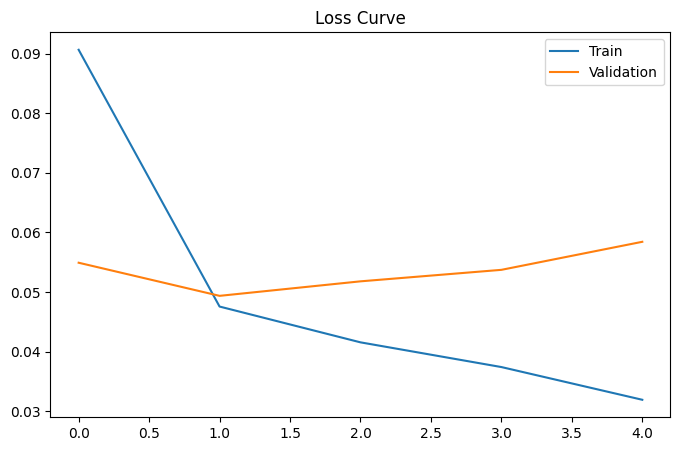

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Train")

plt.plot(history.history["val_loss"], label="Validation")

plt.legend()

plt.title("Loss Curve")

plt.show()

10. Generate Predictions and Evaluate Model Performance

In [ ]:
y_prob = model.predict(X_test_pad)

y_pred = (y_prob >= 0.5).astype(int)

998/998 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step


In [ ]:
print("="*50)

print("Hamming Loss")
print(hamming_loss(y_test, y_pred))

print("="*50)

print("Micro Precision")
print(precision_score(y_test, y_pred, average="micro"))

print("="*50)

print("Micro Recall")
print(recall_score(y_test, y_pred, average="micro"))

print("="*50)

print("Micro F1")
print(f1_score(y_test, y_pred, average="micro"))

print("="*50)

print("Macro F1")
print(f1_score(y_test, y_pred, average="macro"))

print("="*50)

print("ROC AUC")
print(
    roc_auc_score(
        y_test,
        y_prob,
        average="macro"
    )
)

Hamming Loss
0.017262091298443537
Micro Precision
0.8227215980024969
Micro Recall
0.6662333911034084
Micro F1
0.7362540898571542
Macro F1
0.4436583901895137
ROC AUC
0.9752422459568408


11. Generate Classification Report for Each Toxicity Label

In [ ]:
for i, label in enumerate(target_columns):

    print("="*70)

    print(label.upper())

    print(
        classification_report(
            y_test[label],
            y_pred[:, i]
        )
    )

TOXIC
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     28860
           1       0.86      0.73      0.79      3050

    accuracy                           0.96     31910
   macro avg       0.92      0.86      0.89     31910
weighted avg       0.96      0.96      0.96     31910

SEVERE_TOXIC
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     31614
           1       0.54      0.28      0.37       296

    accuracy                           0.99     31910
   macro avg       0.77      0.64      0.68     31910
weighted avg       0.99      0.99      0.99     31910

OBSCENE
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     30255
           1       0.82      0.80      0.81      1655

    accuracy                           0.98     31910
   macro avg       0.91      0.89      0.90     31910
weighted avg       0.98      0.98      0.98    

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m